<center><h1>Zheng_Yifei_HW6</h1></center>

Name: Yifei Zheng
<br>
Github Username: yyl-ff
<br>
USC ID: 8538054131

## 1. Tree-Based Methods

Import packages

In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### (a) Download the APS Failure data

In [142]:
train_data = pd.read_csv(
    "aps+failure+at+scania+trucks/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_data = pd.read_csv(
    "aps+failure+at+scania+trucks/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Some common ways to handle missing values are deleting missing data, using mean or median values, KNN imputation, and regression imputation.
In this homework, I use median imputation. Median is less affected by very large or very small values. I calculate the median from the training set and use it to fill missing values in both the training and test sets.

#### (ii) Calculate the coefficient of variation

In [146]:
from sklearn.impute import SimpleImputer

X_train_raw = train_data.drop(columns="class")
X_test_raw = test_data.drop(columns="class")
y_train = train_data["class"].copy()
y_test = test_data["class"].copy()

imputer = SimpleImputer(
    strategy="median"
).set_output(
    transform="pandas"
)

X_train = imputer.fit_transform(X_train_raw)
X_test = imputer.transform(X_test_raw)

cv_table = X_train.agg(
    ["mean", "std"]
).T.rename(
    columns={
        "mean": "Mean",
        "std": "Standard Deviation"
    }
)

cv_table["CV"] = (
    cv_table["Standard Deviation"]
    / cv_table["Mean"]
)

cv_table = cv_table.sort_values(
    "CV",
    ascending=False
)

#### (iii) Plot a correlation matrix

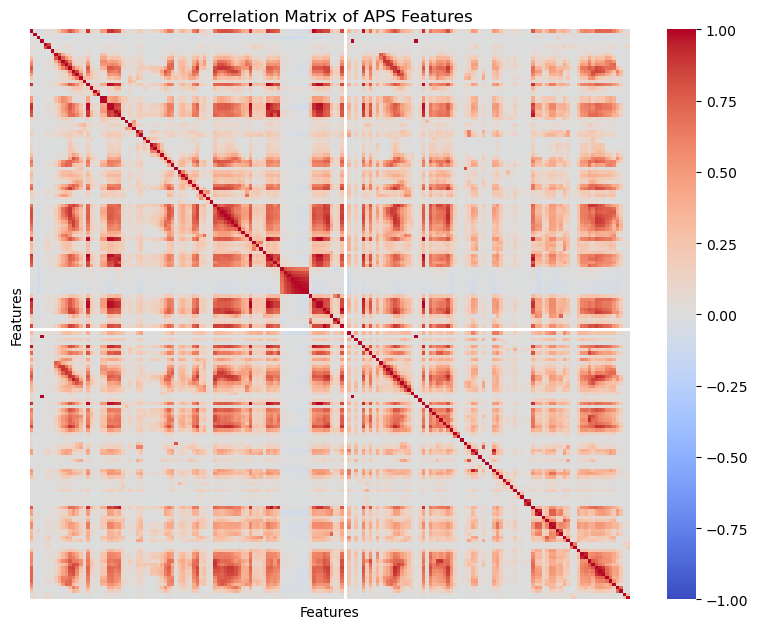

In [148]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(8, 6.4))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of APS Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

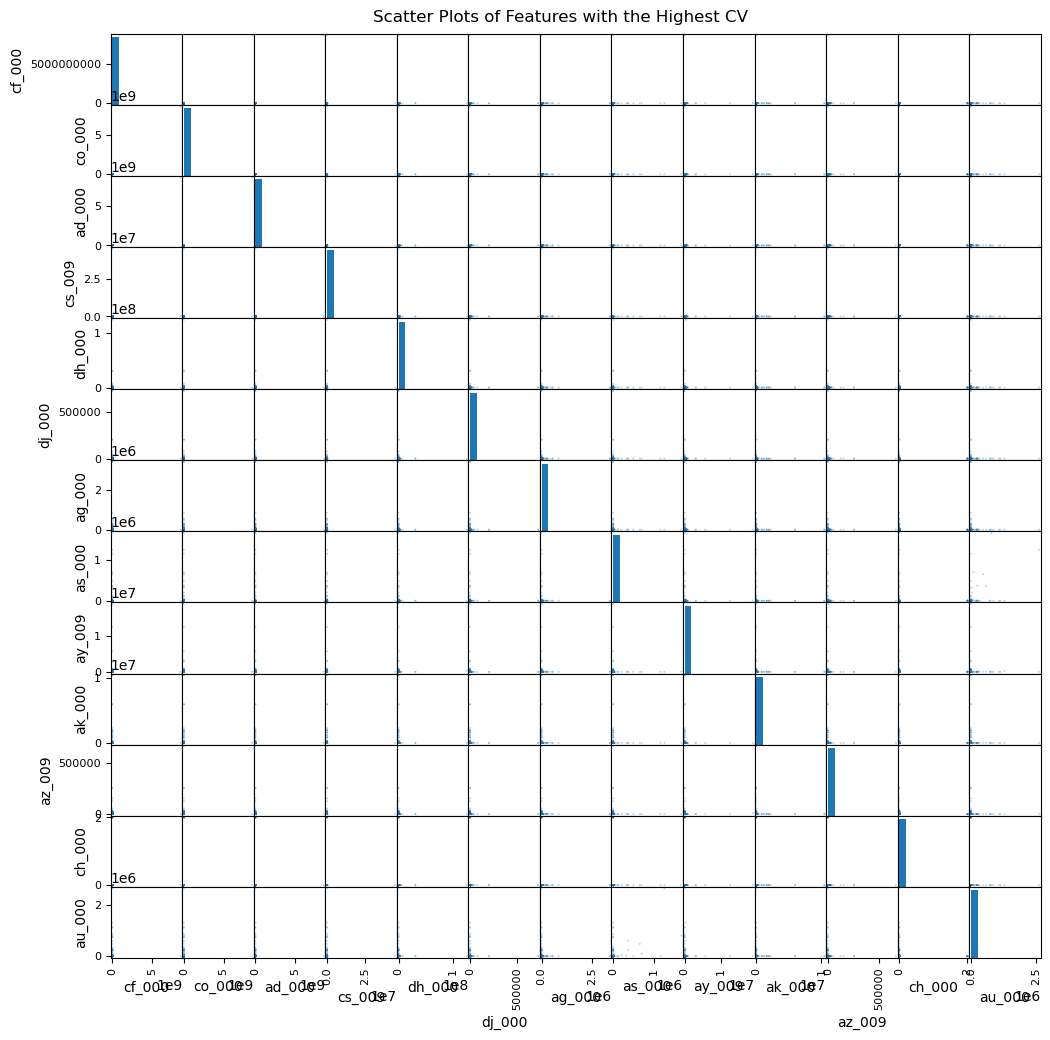

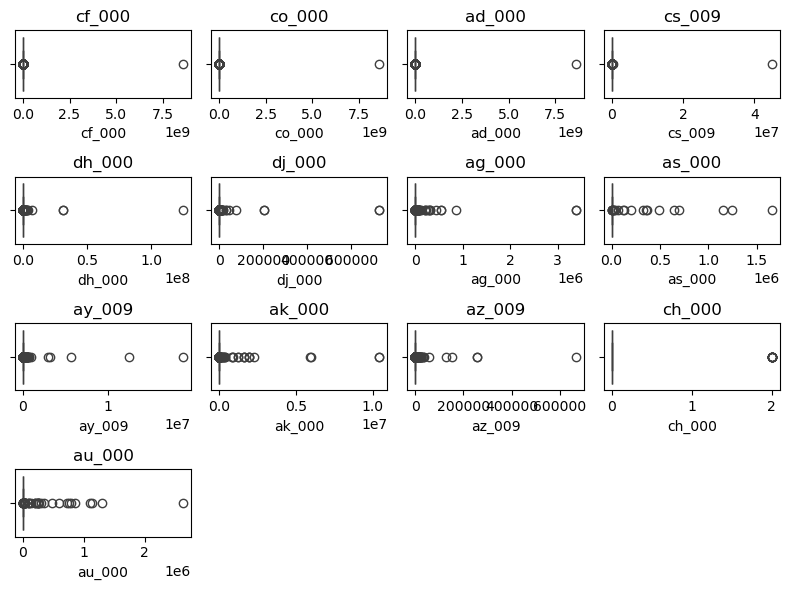

In [158]:
number_of_features = int(
    np.floor(
        np.sqrt(170)
    )
)

selected_features = cv_table.head(number_of_features).index.tolist()
scatter_data = X_train[selected_features]

pd.plotting.scatter_matrix(
    scatter_data,
    figsize=(12, 12),
    diagonal="hist",
    alpha=0.3,
    s=8
)

plt.suptitle("Scatter Plots of Features with the Highest CV", y=0.9)
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(8, 6))

axes = axes.flatten()

for index, feature in enumerate(
    selected_features
):
    sns.boxplot(
        x=X_train[feature],
        ax=axes[index]
    )

    axes[index].set_title(feature)

for index in range(
    len(selected_features),
    len(axes)
):
    fig.delaxes(axes[index])

plt.tight_layout()
plt.show()

The scatter plots show some possible relationships between the selected features. However, we cannot decide if a feature is significant only from the scatter plots. We need statistical tests or classification models to check the significance.

#### (v) Is this data set imbalanced?

In [161]:
class_counts = y_train.value_counts()

print("Negative samples:", class_counts["neg"])
print("Positive samples:", class_counts["pos"])
print("Negative class percentage:", f"{class_counts['neg'] / len(y_train) * 100:.2f}%")
print("Positive class percentage:", f"{class_counts['pos'] / len(y_train) * 100:.2f}%")

Negative samples: 59000
Positive samples: 1000
Negative class percentage: 98.33%
Positive class percentage: 1.67%


The training set has 59,000 negative samples and 1,000 positive samples. The positive class is only 1.67% of the training data. Therefore, the dataset is highly imbalanced.

### (c) Train a random forest

,Dataset,AUC,Misclassification Error
0,Training,1.000000,0.000000
1,Testing,0.994352,0.007313


Training Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,59000,0
Actual Positive,0,1000


Testing Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,15609,16
Actual Positive,101,274


OOB Error: 0.005833
Test Error: 0.007313


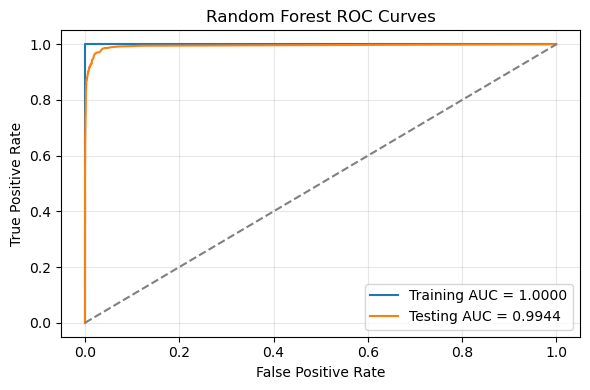

In [163]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

def evaluate_model(
    model,
    X_train,
    X_test,
    y_train,
    y_test,
    labels,
    positive_label,
    model_name
):
    result = {}
    metrics = []

    for name, key, X, y in [
        ("Training", "train", X_train, y_train),
        ("Testing", "test", X_test, y_test)
    ]:
        predictions = model.predict(X)
        positive_index = list(model.classes_).index(positive_label)
        probabilities = model.predict_proba(X)[:, positive_index]
        matrix = confusion_matrix(y, predictions, labels=labels)
        auc = roc_auc_score(y, probabilities)
        error = np.mean(predictions != np.asarray(y))
        fpr, tpr, _ = roc_curve(
            y,
            probabilities,
            pos_label=positive_label
        )

        result[f"{key}_predictions"] = predictions
        result[f"{key}_probabilities"] = probabilities
        result[f"{key}_matrix"] = matrix
        result[f"{key}_auc"] = auc
        result[f"{key}_error"] = error
        result[f"{key}_fpr"] = fpr
        result[f"{key}_tpr"] = tpr

        metrics.append({
            "Dataset": name,
            "AUC": auc,
            "Misclassification Error": error
        })

    display(pd.DataFrame(metrics))

    for name, key in [
        ("Training", "train"),
        ("Testing", "test")
    ]:
        print(f"{name} Confusion Matrix:")
        display(
            pd.DataFrame(
                result[f"{key}_matrix"],
                index=[
                    "Actual Negative",
                    "Actual Positive"
                ],
                columns=[
                    "Predicted Negative",
                    "Predicted Positive"
                ]
            )
        )

    if hasattr(model, "oob_score_"):
        result["oob_error"] = 1 - model.oob_score_
        print(
            f"OOB Error: {result['oob_error']:.6f}\n"
            f"Test Error: {result['test_error']:.6f}"
        )
    else:
        print(f"Test Error: {result['test_error']:.6f}")

    plt.figure(figsize=(6, 4))
    plt.plot(result["train_fpr"], result["train_tpr"], label=f"Training AUC = {result['train_auc']:.4f}")
    plt.plot(result["test_fpr"], result["test_tpr"], label=f"Testing AUC = {result['test_auc']:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} ROC Curves")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return result

random_forest = RandomForestClassifier(
    n_estimators=200,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_result = evaluate_model(
    random_forest,
    X_train,
    X_test,
    y_train,
    y_test,
    ["neg", "pos"],
    "pos",
    "Random Forest"
)

The random forest performs very well on the training set. Its training AUC is 1.0000 and the training error is 0. The test AUC is 0.9944 and the test error is 0.0073.

In the test set, 16 negative samples are predicted as positive, and 101 positive samples are predicted as negative. Although the total test error is low, the model misses many positive samples because the dataset is highly imbalanced.

The OOB error is 0.0058, which is close to the test error of 0.0073. Therefore, the OOB error gives a reasonable estimate of the test error.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be handled by giving a larger weight to the minority class. It can also be handled by oversampling the minority class or undersampling the majority class.

In this part, I use balanced class weights. The model gives a larger penalty when a positive sample is classified incorrectly.

,Dataset,AUC,Misclassification Error
0,Training,1.000000,0.000000
1,Testing,0.993093,0.010875


Training Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,59000,0
Actual Positive,0,1000


Testing Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,15610,15
Actual Positive,159,216


OOB Error: 0.007933
Test Error: 0.010875


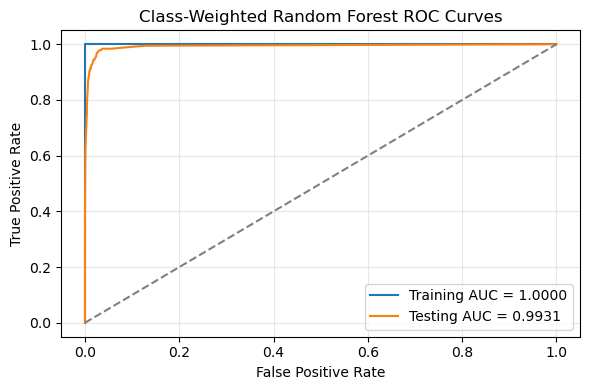

,Model,Test AUC,Test Error,OOB Error,False Positives,False Negatives
0,Original Random Forest,0.994352,0.007313,0.005833,16,101
1,Class-Weighted Random Forest,0.993093,0.010875,0.007933,15,159


In [165]:
weighted_random_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

weighted_random_forest.fit(X_train, y_train)

weighted_rf_result = evaluate_model(
    weighted_random_forest,
    X_train,
    X_test,
    y_train,
    y_test,
    ["neg", "pos"],
    "pos",
    "Class-Weighted Random Forest"
)

rf_comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Class-Weighted Random Forest"],
    "Test AUC": [rf_result["test_auc"], weighted_rf_result["test_auc"]],
    "Test Error": [rf_result["test_error"], weighted_rf_result["test_error"]],
    "OOB Error": [rf_result["oob_error"], weighted_rf_result["oob_error"]],
    "False Positives": [rf_result["test_matrix"][0, 1], weighted_rf_result["test_matrix"][0, 1]],
    "False Negatives": [rf_result["test_matrix"][1, 0], weighted_rf_result["test_matrix"][1, 0]]
})

display(rf_comparison)

The balanced random forest has a test AUC of 0.9931 and a test error of 0.0109. Its OOB error is 0.0079, which is close to the test error.

Compared with the unbalanced random forest, the balanced model has a slightly lower AUC and a higher test error. The number of false positives decreases from 16 to 15, but the number of false negatives increases from 101 to 159.

In this case, using balanced class weights does not improve the model. The original random forest performs better on the test set. This shows that class weighting does not always give better results, and its effect depends on the data and model.

### (e) XGBoost and Model Trees

,Alpha,CV Accuracy,CV Error
0,0.000,0.993433,0.006567
1,0.001,0.993567,0.006433
2,0.010,0.993417,0.006583
3,0.100,0.993417,0.006583
4,1.000,0.993567,0.006433
5,10.000,0.992367,0.007633
6,100.000,0.988733,0.011267


Best Alpha: 0.001
Best Cross-Validation Error: 0.006433


,Dataset,AUC,Misclassification Error
0,Training,0.997552,0.003417
1,Testing,0.996006,0.007500


Training Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,58968,32
Actual Positive,173,827


Testing Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,15608,17
Actual Positive,103,272


Test Error: 0.007500


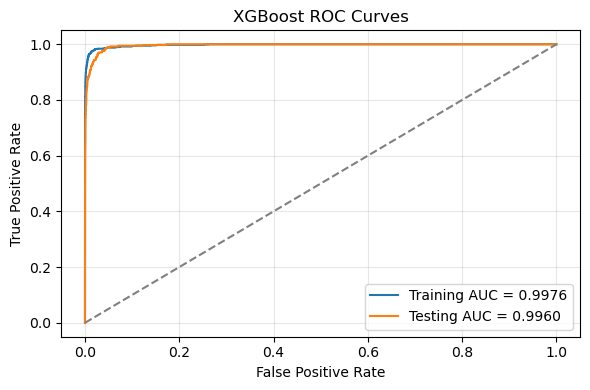

In [167]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

y_train_binary = y_train.map({"neg": 0, "pos": 1})
y_test_binary = y_test.map({"neg": 0, "pos": 1})

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=150,
    max_depth=3,
    learning_rate=0.1,
    subsample=1,
    colsample_bytree=1,
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

alpha_values = [0, 0.001, 0.01, 0.1, 1, 10, 100]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={
        "reg_alpha": alpha_values
    },
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train_binary)
best_xgb_model = xgb_search.best_estimator_

cv_results = pd.DataFrame({
    "Alpha": xgb_search.cv_results_["param_reg_alpha"].astype(float),
    "CV Accuracy": xgb_search.cv_results_["mean_test_score"],
    "CV Error": 1 - xgb_search.cv_results_["mean_test_score"]
}).sort_values("Alpha")

display(cv_results)

print(
    f"Best Alpha: {xgb_search.best_params_['reg_alpha']}\n"
    f"Best Cross-Validation Error: "
    f"{1 - xgb_search.best_score_:.6f}"
)

xgb_result = evaluate_model(
    best_xgb_model,
    X_train,
    X_test,
    y_train_binary,
    y_test_binary,
    [0, 1],
    1,
    "XGBoost"
)

The best L1 regularization parameter is 0.001. Its 5-fold cross-validation error is 0.0064, while the test error is 0.0075. These two errors are close, so the cross-validation result gives a reasonable estimate of the test error.

The training AUC is 0.9976 and the test AUC is 0.9960. Both values are close to 1, so the model has good classification performance.

In the test set, 17 negative samples are predicted as positive, and 103 positive samples are predicted as negative. The model still misses some positive samples because the training data is highly imbalanced.

### (f) Use SMOTE to pre-process your data

SMOTE creates new minority-class samples using nearby minority samples. It should only be applied to the training part of each cross-validation fold. If SMOTE is applied before cross-validation, information from the validation data may enter the training data.

I use a pipeline to apply standardization and SMOTE inside each fold. The test set is not changed by SMOTE.

,Alpha,CV Accuracy,CV Error
0,0.000,0.982217,0.017783
1,0.001,0.982183,0.017817
2,0.010,0.982100,0.017900
3,0.100,0.982533,0.017467
4,1.000,0.982817,0.017183
5,10.000,0.981933,0.018067
6,100.000,0.977317,0.022683


Best SMOTE Alpha: 1
Best SMOTE Cross-Validation Error: 0.017183


,Dataset,AUC,Misclassification Error
0,Training,0.995471,0.015967
1,Testing,0.993009,0.016625


Training Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,58101,899
Actual Positive,59,941


Testing Confusion Matrix:


,Predicted Negative,Predicted Positive
Actual Negative,15393,232
Actual Positive,34,341


Test Error: 0.016625


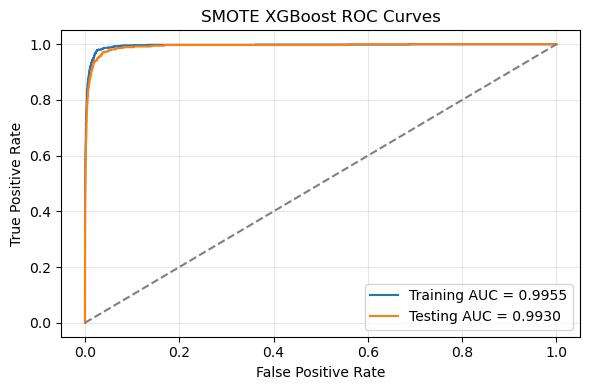

,Model,Best Alpha,CV Error,Test Error,Test AUC,False Positives,False Negatives
0,XGBoost without SMOTE,0.001,0.006433,0.007500,0.996006,17,103
1,XGBoost with SMOTE,1.000,0.017183,0.016625,0.993009,232,34


In [169]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

smote_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("xgb", xgb_model)
])

smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid={"xgb__reg_alpha": alpha_values},
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

smote_search.fit(X_train, y_train_binary)
best_smote_model = smote_search.best_estimator_

smote_cv_results = pd.DataFrame({
    "Alpha": smote_search.cv_results_["param_xgb__reg_alpha"].astype(float),
    "CV Accuracy": smote_search.cv_results_["mean_test_score"],
    "CV Error": 1 - smote_search.cv_results_["mean_test_score"]
}).sort_values("Alpha")

display(smote_cv_results)

print(
    f"Best SMOTE Alpha: "
    f"{smote_search.best_params_['xgb__reg_alpha']}\n"
    f"Best SMOTE Cross-Validation Error: "
    f"{1 - smote_search.best_score_:.6f}"
)

smote_result = evaluate_model(
    best_smote_model,
    X_train,
    X_test,
    y_train_binary,
    y_test_binary,
    [0, 1],
    1,
    "SMOTE XGBoost"
)

xgb_comparison = pd.DataFrame({
    "Model": ["XGBoost without SMOTE", "XGBoost with SMOTE"],
    "Best Alpha": [xgb_search.best_params_["reg_alpha"], smote_search.best_params_["xgb__reg_alpha"]],
    "CV Error": [1 - xgb_search.best_score_, 1 - smote_search.best_score_],
    "Test Error": [xgb_result["test_error"], smote_result["test_error"]],
    "Test AUC": [xgb_result["test_auc"], smote_result["test_auc"]],
    "False Positives": [xgb_result["test_matrix"][0, 1], smote_result["test_matrix"][0, 1]],
    "False Negatives": [xgb_result["test_matrix"][1, 0], smote_result["test_matrix"][1, 0]]
})

display(xgb_comparison)

The best L1 regularization parameter for the SMOTE model is 1. The cross-validation error is 0.0172 and the test error is 0.0166. These two values are close, so the cross-validation result gives a reasonable estimate of the test error.

After using SMOTE, the number of false negatives decreases from 103 to 34. The positive-class recall increases from 72.53% to 90.93%. Therefore, SMOTE helps the model find more positive samples.

However, the number of false positives increases from 17 to 232. The test error increases from 0.0075 to 0.0166, and the test AUC decreases slightly from 0.9960 to 0.9930.

Therefore, SMOTE improves the detection of the minority class, but it produces more false alarms and a higher total error. It may still be useful for this dataset because missing a truck failure can be more costly than a false alarm.

## 2. ISLR 6.6.3

## (a) Training RSS

The correct answer is **iv. Steadily decrease**.

When \(s=0\), all coefficients are zero. As \(s\) increases, the constraint becomes less strict and the model can use more predictors. The model becomes more flexible, so the training RSS decreases.


## (b) Test RSS

The correct answer is **ii. Decrease initially, and then eventually start increasing in a U shape**.

At first, increasing \(s\) makes the model more flexible and reduces underfitting. However, when \(s\) becomes too large, the model may overfit the training data. Therefore, the test RSS first decreases and then increases.

## (c) Variance

The correct answer is **iii. Steadily increase**.

As \(s\) increases, the model becomes more flexible. Its results become more sensitive to changes in the training data. Therefore, the variance steadily increases.

## (d) Squared bias

The correct answer is **iv. Steadily decrease**.

When \(s\) is small, the coefficients are strongly restricted, so the model is simple and has high bias. As \(s\) increases, the restriction becomes weaker and the model becomes more flexible. Therefore, the squared bias steadily decreases.

## (e) Irreducible error

The correct answer is **v. Remain constant**.

The irreducible error comes from random noise in the data. It does not depend on the model or the value of \(s\). Therefore, it remains constant.

## 3. ISLR 6.6.5

## (a) Ridge regression optimization problem

The ridge regression optimization problem is

$$
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(\beta_1^2+\beta_2^2).
$$

Because $x_{11}=x_{12}$, $x_{21}=x_{22}$, $y_2=-y_1$, and $x_{21}=-x_{11}$, the problem can be simplified to

$$
2[y_1-x_{11}(\beta_1+\beta_2)]^2
+
\lambda(\beta_1^2+\beta_2^2).
$$

## (b) Ridge coefficient estimates

For ridge regression, the derivatives with respect to $\beta_1$ and $\beta_2$ are

$$
-4x_{11}[y_1-x_{11}(\beta_1+\beta_2)]
+2\lambda\beta_1=0,
$$

and

$$
-4x_{11}[y_1-x_{11}(\beta_1+\beta_2)]
+2\lambda\beta_2=0.
$$

Subtracting the two equations gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Therefore,

$$
\hat{\beta}_1=\hat{\beta}_2.
$$

Ridge regression gives the same coefficient to the two identical predictors.

## (c) Lasso optimization problem

The lasso optimization problem is

$$
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(|\beta_1|+|\beta_2|).
$$

Using the conditions in the question, it becomes

$$
2[y_1-x_{11}(\beta_1+\beta_2)]^2
+
\lambda(|\beta_1|+|\beta_2|).
$$

## (d) Non-unique lasso coefficients

Let

$$
\theta=\beta_1+\beta_2.
$$

The fitted values only depend on $\theta$. They do not depend on the individual values of $\beta_1$ and $\beta_2$.

For a fixed value of $\theta$, the smallest penalty is

$$
|\beta_1|+|\beta_2|=|\theta|.
$$

If the optimal value $\hat{\theta}$ is positive, all pairs

$$
\hat{\beta}_1=t,
\qquad
\hat{\beta}_2=\hat{\theta}-t,
\qquad
0\leq t\leq\hat{\theta}
$$

give the same result.

If $\hat{\theta}$ is negative, all pairs

$$
\hat{\beta}_1=t,
\qquad
\hat{\beta}_2=\hat{\theta}-t,
\qquad
\hat{\theta}\leq t\leq0
$$

give the same result.

Therefore, the lasso coefficients are not unique. Lasso can divide the total coefficient between the two identical predictors in many different ways.

## 4. ISLR 8.4.5

For the majority vote approach, each tree predicts red when the probability is greater than 0.5.

Six trees predict red and four trees predict green. Therefore, the final classification by majority vote is **red**.

For the average probability approach, the average probability is

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=0.45.
$$

Since 0.45 is less than 0.5, the final classification based on the average probability is **green**.

## 5. ISLR 9.7.3

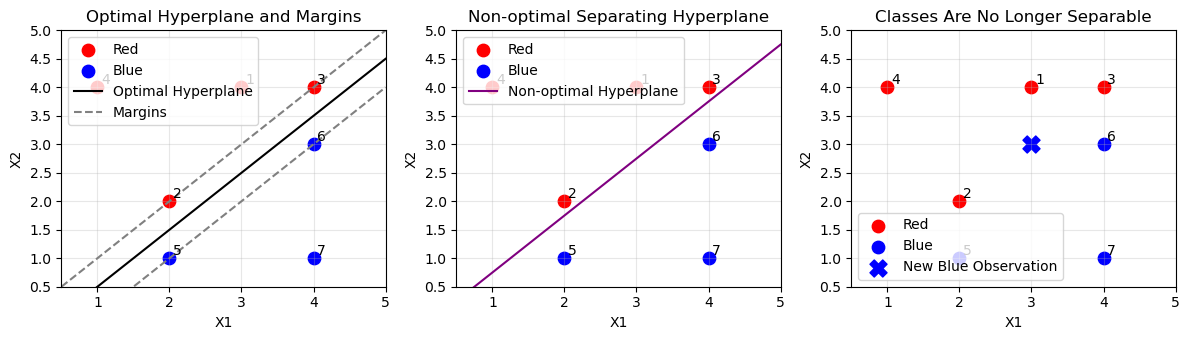

In [171]:
red_points = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4]
])

blue_points = np.array([
    [2, 1],
    [4, 3],
    [4, 1]
])

x_values = np.linspace(0.5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax in axes:
    ax.scatter(
        red_points[:, 0],
        red_points[:, 1],
        color="red",
        s=80,
        label="Red"
    )

    ax.scatter(
        blue_points[:, 0],
        blue_points[:, 1],
        color="blue",
        s=80,
        label="Blue"
    )

    for index, point in enumerate(
        np.vstack([red_points, blue_points]),
        start=1
    ):
        ax.text(point[0] + 0.05, point[1] + 0.05, str(index))

    ax.set_xlim(0.5, 5)
    ax.set_ylim(0.5, 5)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(alpha=0.3)

axes[0].plot(
    x_values,
    x_values - 0.5,
    color="black",
    label="Optimal Hyperplane"
)
axes[0].plot(
    x_values,
    x_values,
    linestyle="--",
    color="gray",
    label="Margins"
)
axes[0].plot(
    x_values,
    x_values - 1,
    linestyle="--",
    color="gray"
)
axes[0].set_title("Optimal Hyperplane and Margins")
axes[1].plot(
    x_values,
    x_values - 0.25,
    color="purple",
    label="Non-optimal Hyperplane"
)
axes[1].set_title("Non-optimal Separating Hyperplane")
axes[2].scatter(
    3,
    3,
    color="blue",
    marker="X",
    s=150,
    label="New Blue Observation"
)
axes[2].set_title("Classes Are No Longer Separable")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

## (a)

The red observations are:
- (3, 4)
- (2, 2)
- (4, 4)
- (1, 4)

The blue observations are:
- (2, 1)
- (4, 3)
- (4, 1)

The observations are shown in the plots above.

## (b)

The optimal separating hyperplane is:
0.5 - X₁ + X₂ = 0

It can also be written as:
X₂ = X₁ - 0.5

This line is halfway between the closest red and blue observations.

## (c)

The coefficients of the maximal margin classifier are:
- β₀ = 0.5
- β₁ = -1
- β₂ = 1

The classification rule is:
- Classify an observation as Red if 0.5 - X₁ + X₂ > 0.
- Classify an observation as Blue otherwise.

## (d)

The two margin boundaries are: X₂ = X₁ and X₂ = X₁ - 1

The optimal hyperplane is halfway between these two lines.

The distance from the optimal hyperplane to each margin boundary is: 0.5 / √2

## (e)

The support vectors are observations 2, 3, 5, and 6:
- Observation 2: (2, 2), Red
- Observation 3: (4, 4), Red
- Observation 5: (2, 1), Blue
- Observation 6: (4, 3), Blue

These observations lie on the two margin boundaries.

## (f)

Observation 7 is not a support vector because it is far from the separating hyperplane.

A small movement of observation 7 will not change the closest observations between the two classes. Therefore, it will not change the maximal margin hyperplane.

## (g)

One possible non-optimal separating hyperplane is: 0.25 - X₁ + X₂ = 0

It can also be written as: X₂ = X₁ - 0.25

This line still separates the two classes. However, it is not halfway between the closest red and blue observations, so its margin is smaller than the optimal margin.

## (h)

We can add a new Blue observation at: (3, 3)

This point lies between the two Red observations (2, 2) and (4, 4). Therefore, it lies inside the area formed by the Red class.

After adding this point, the Red and Blue classes can no longer be completely separated by a linear hyperplane.